Importing all necessary libraries and loading in the CSV

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# from google.colab import drive

# drive.mount('/content/drive')
# uploaded = files.upload()
# house = pd.read_csv('/content/drive/MyDrive/Housing Price data set.csv')
house = pd.read_csv('Housing Price data set.csv')

In [3]:
house

,Unnamed: 0,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,1,42000.0,5850,3,1,2,yes,no,yes,no,no,1,no
1,2,38500.0,4000,2,1,1,yes,no,no,no,no,0,no
2,3,49500.0,3060,3,1,1,yes,no,no,no,no,0,no
3,4,60500.0,6650,3,1,2,yes,yes,no,no,no,0,no
4,5,61000.0,6360,2,1,1,yes,no,no,no,no,0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...
541,542,91500.0,4800,3,2,4,yes,yes,no,no,yes,0,no
542,543,94000.0,6000,3,2,4,yes,no,no,no,yes,0,no
543,544,103000.0,6000,3,2,4,yes,yes,no,no,yes,1,no
544,545,105000.0,6000,3,2,2,yes,yes,no,no,yes,1,no


Basic visualization of the frequency per unit observation of our data. Additionally identifying the statistical values via .describe()

array([[<Axes: title={'center': 'Unnamed: 0'}>,
        <Axes: title={'center': 'price'}>,
        <Axes: title={'center': 'lotsize'}>],
       [<Axes: title={'center': 'bedrooms'}>,
        <Axes: title={'center': 'bathrms'}>,
        <Axes: title={'center': 'stories'}>],
       [<Axes: title={'center': 'garagepl'}>, <Axes: >, <Axes: >]],
      dtype=object)

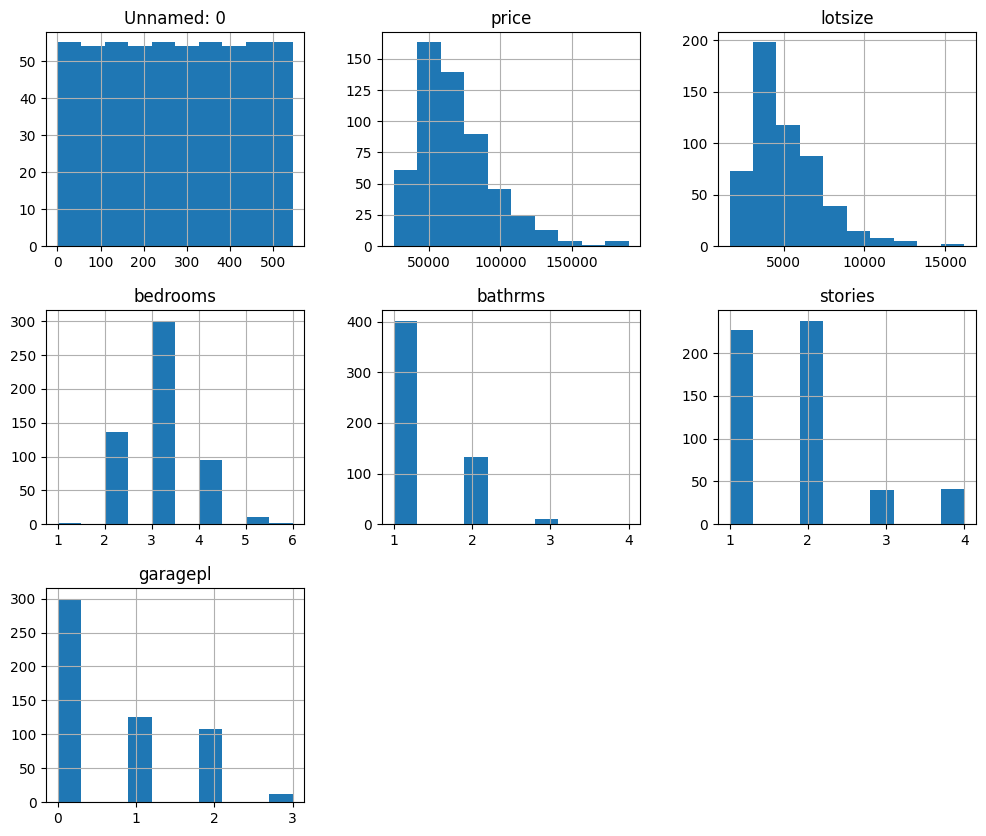

In [4]:
house.describe()
house.hist(figsize=(12,10))

Identifying variable types to accurately convert based on programming requirements

In [5]:
house.dtypes

Unnamed: 0      int64
price         float64
lotsize         int64
bedrooms        int64
bathrms         int64
stories         int64
driveway       object
recroom        object
fullbase       object
gashw          object
airco          object
garagepl        int64
prefarea       object
dtype: object

Converting logicals to numeric

In [6]:
house[['recroom','fullbase','gashw','airco','prefarea','driveway']].replace({'yes': 1, 'no': 0})

C:\Users\asher\AppData\Local\Temp\ipykernel_9624\3099767883.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  house[['recroom','fullbase','gashw','airco','prefarea','driveway']].replace({'yes': 1, 'no': 0})


,recroom,fullbase,gashw,airco,prefarea,driveway
0,0,1,0,0,0,1
1,0,0,0,0,0,1
2,0,0,0,0,0,1
3,1,0,0,0,0,1
4,0,0,0,0,0,1
...,...,...,...,...,...,...
541,1,0,0,1,0,1
542,0,0,0,1,0,1
543,1,0,0,1,0,1
544,1,0,0,1,0,1


Maintaining original state by adding the adjusted to a new variable for the sake of consistency

In [7]:
adjusted = house.copy()
adjusted[['recroom','fullbase','gashw','airco','prefarea','driveway']] = adjusted[['recroom','fullbase','gashw','airco','prefarea','driveway']].replace({'yes': 1, 'no': 0})
adjusted

C:\Users\asher\AppData\Local\Temp\ipykernel_9624\5350007.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  adjusted[['recroom','fullbase','gashw','airco','prefarea','driveway']] = adjusted[['recroom','fullbase','gashw','airco','prefarea','driveway']].replace({'yes': 1, 'no': 0})


,Unnamed: 0,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,gashw,airco,garagepl,prefarea
0,1,42000.0,5850,3,1,2,1,0,1,0,0,1,0
1,2,38500.0,4000,2,1,1,1,0,0,0,0,0,0
2,3,49500.0,3060,3,1,1,1,0,0,0,0,0,0
3,4,60500.0,6650,3,1,2,1,1,0,0,0,0,0
4,5,61000.0,6360,2,1,1,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
541,542,91500.0,4800,3,2,4,1,1,0,0,1,0,0
542,543,94000.0,6000,3,2,4,1,0,0,0,1,0,0
543,544,103000.0,6000,3,2,4,1,1,0,0,1,1,0
544,545,105000.0,6000,3,2,2,1,1,0,0,1,1,0


In [8]:
# sns.heatmap(adjusted.corr())

In [9]:
print(house.value_counts())

Unnamed: 0  price     lotsize  bedrooms  bathrms  stories  driveway  recroom  fullbase  gashw  airco  garagepl  prefarea
1           42000.0   5850     3         1        2        yes       no       yes       no     no     1         no          1
2           38500.0   4000     2         1        1        yes       no       no        no     no     0         no          1
3           49500.0   3060     3         1        1        yes       no       no        no     no     0         no          1
4           60500.0   6650     3         1        2        yes       yes      no        no     no     0         no          1
5           61000.0   6360     2         1        1        yes       no       no        no     no     0         no          1
                                                                                                                           ..
542         91500.0   4800     3         2        4        yes       yes      no        no     yes    0         no         

In [10]:
print(house.columns.tolist())

['Unnamed: 0', 'price', 'lotsize', 'bedrooms', 'bathrms', 'stories', 'driveway', 'recroom', 'fullbase', 'gashw', 'airco', 'garagepl', 'prefarea']


dropping columns that don't contribute much to the goal

In [11]:
house_core = adjusted.drop(columns=['Unnamed: 0','gashw'])
house_core

,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,airco,garagepl,prefarea
0,42000.0,5850,3,1,2,1,0,1,0,1,0
1,38500.0,4000,2,1,1,1,0,0,0,0,0
2,49500.0,3060,3,1,1,1,0,0,0,0,0
3,60500.0,6650,3,1,2,1,1,0,0,0,0
4,61000.0,6360,2,1,1,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
541,91500.0,4800,3,2,4,1,1,0,1,0,0
542,94000.0,6000,3,2,4,1,0,0,1,0,0
543,103000.0,6000,3,2,4,1,1,0,1,1,0
544,105000.0,6000,3,2,2,1,1,0,1,1,0


Identifying impact at a low level

<Axes: >

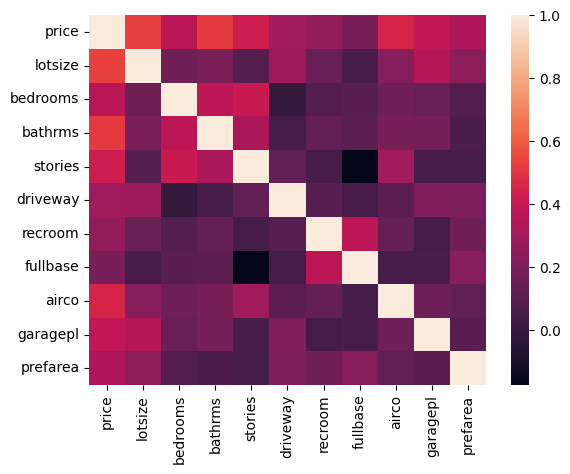

In [12]:
sns.heatmap(house_core.corr())

More statistical Inference

In [13]:
house_core.describe()

,price,lotsize,bedrooms,bathrms,stories,driveway,recroom,fullbase,airco,garagepl,prefarea
count,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000,546.000000
mean,68121.597070,5150.265568,2.965201,1.285714,1.807692,0.858974,0.177656,0.349817,0.316850,0.692308,0.234432
std,26702.670926,2168.158725,0.737388,0.502158,0.868203,0.348367,0.382573,0.477349,0.465675,0.861307,0.424032
min,25000.000000,1650.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,49125.000000,3600.000000,2.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,62000.000000,4600.000000,3.000000,1.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,82000.000000,6360.000000,3.000000,2.000000,2.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000
max,190000.000000,16200.000000,6.000000,4.000000,4.000000,1.000000,1.000000,1.000000,1.000000,3.000000,1.000000


Checking for NA values to ensure no missing data messes up further analysis

In [14]:
house_core.isna().sum()

price       0
lotsize     0
bedrooms    0
bathrms     0
stories     0
driveway    0
recroom     0
fullbase    0
airco       0
garagepl    0
prefarea    0
dtype: int64

Understanding the relationship of bedrooms to housing price. Identify harmful data and removing that data

<Axes: xlabel='bedrooms', ylabel='price'>

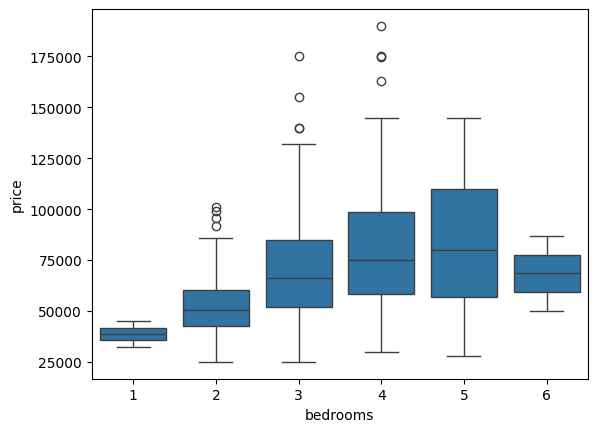

In [15]:
sns.boxplot(data=house_core, x='bedrooms', y='price')

cleaning up the plot as to have consistent and understandable data

<Axes: xlabel='bedrooms', ylabel='price'>

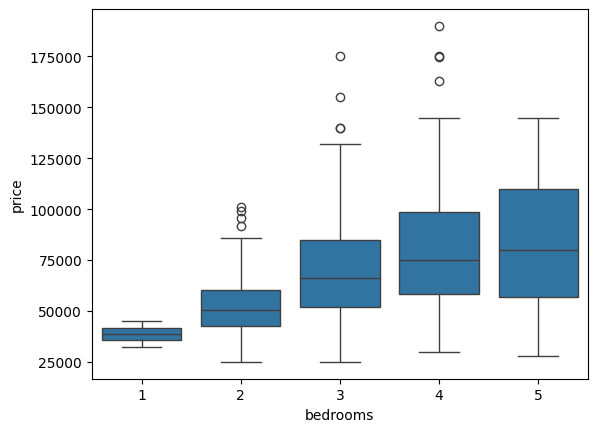

In [16]:
bdrs_5 = house_core[house_core['bedrooms'] < 6]
sns.boxplot(data=bdrs_5, x='bedrooms', y='price')

Apply same plot to Stories

<Axes: xlabel='stories', ylabel='price'>

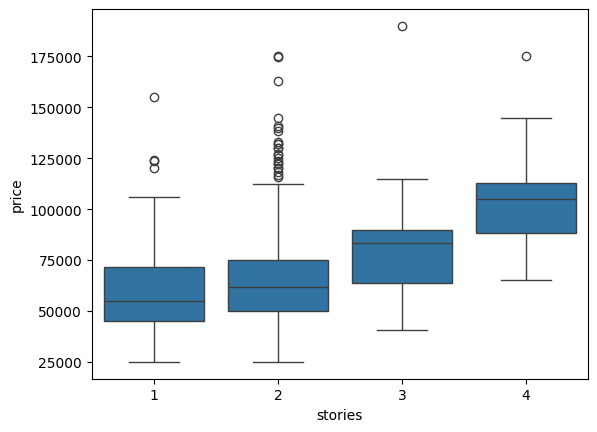

In [17]:
sns.boxplot(data=house_core, x='stories', y='price')

Identifying relationship via scatter for more diverse range of numbers

<Axes: xlabel='lotsize', ylabel='price'>

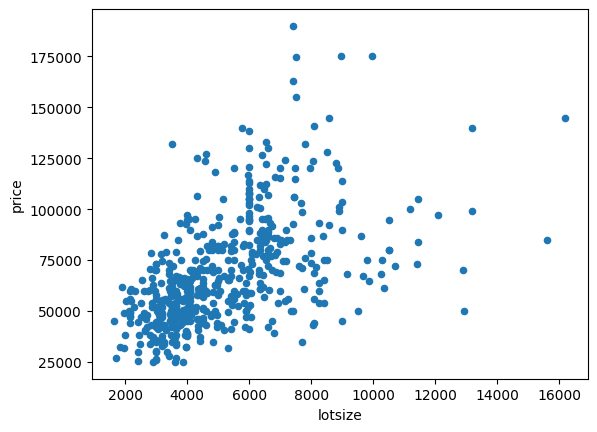

In [18]:
house_core.plot.scatter(x='lotsize', y='price')

<Axes: xlabel='bathrms', ylabel='price'>

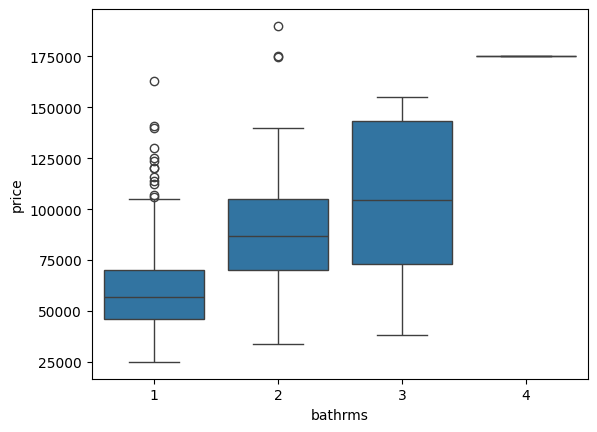

In [19]:
sns.boxplot(data=house_core, x='bathrms', y='price')

<Axes: xlabel='airco', ylabel='price'>

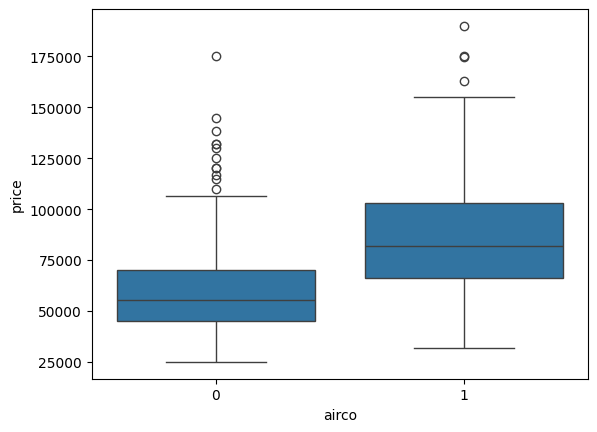

In [20]:
sns.boxplot(data=house_core, x='airco', y='price')

In [21]:
hadj = house_core[(house_core['bedrooms'] < 6) & (house_core['lotsize'] <= 11000)]

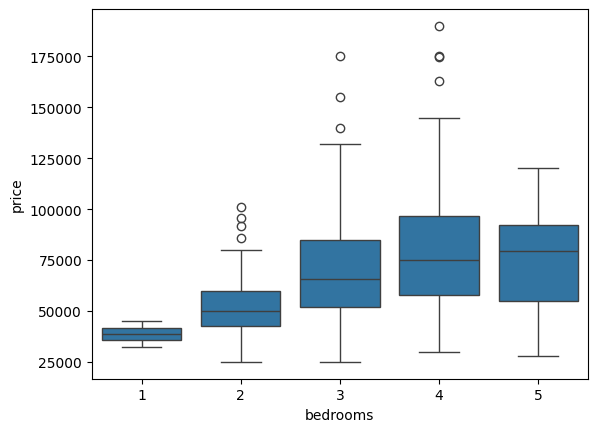

In [22]:
bdrs = sns.boxplot(data=hadj, x='bedrooms', y='price')

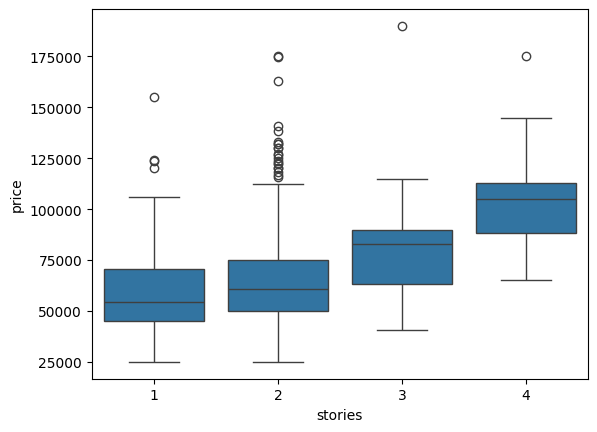

In [23]:
strs = sns.boxplot(data=hadj, x='stories', y='price')

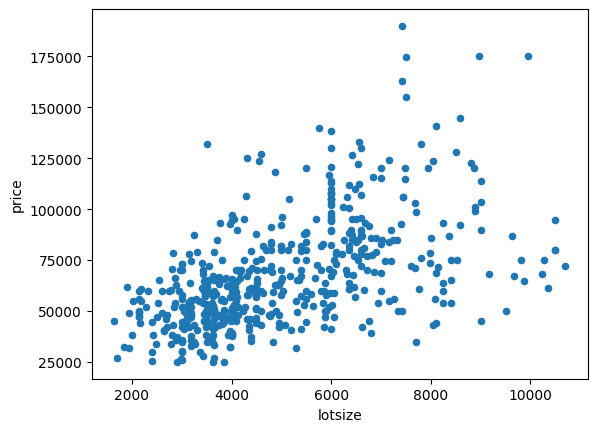

In [24]:
lts = hadj.plot.scatter(x='lotsize', y='price')

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [26]:
x = hadj.drop(columns=['price'])
y = np.log(hadj['price'])

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=.2, random_state=42)

scaler = StandardScaler()
strain = scaler.fit_transform(X_train)
stest = scaler.transform(X_test)

In [27]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

In [28]:
model = LinearRegression()
model.fit(strain, y_train)
pred = model.predict(stest)
predictions = np.exp(pred)
ytdollars = np.exp(y_test)

In [29]:
predictions_train = model.predict(strain)

In [30]:
ptd = np.exp(predictions_train)
ytd = np.exp(y_train)

In [31]:
rmse = np.sqrt(mean_squared_error(ytdollars, predictions))
r2 = r2_score(ytdollars, predictions)
r2train = r2_score(ytd, ptd)
print(f"RMSE: {rmse}")
print(f"R2: {r2}")
print(f"R2 Train: {r2train}")

RMSE: 14540.951348868102
R2: 0.6321082401270561
R2 Train: 0.665411914125601


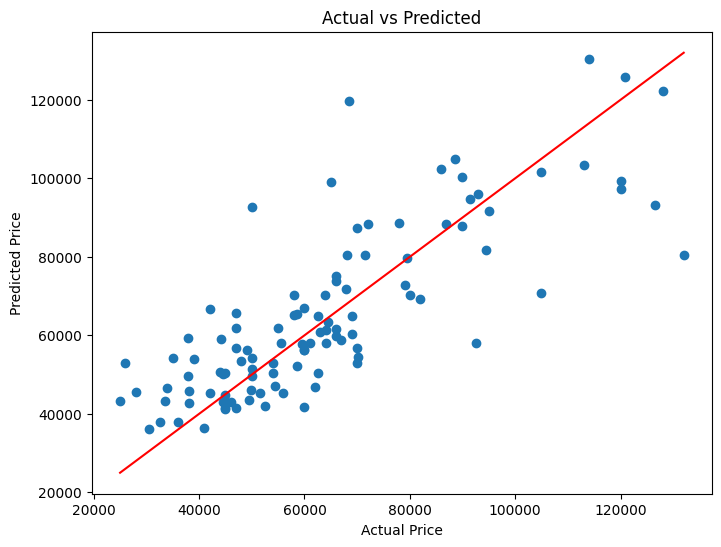

In [32]:
plt.figure(figsize=(8,6))
plt.scatter(ytdollars, predictions)
plt.plot([ytdollars.min(), ytdollars.max()], [ytdollars.min(), ytdollars.max()], color='red')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted')
plt.show()

In [33]:
from sklearn.linear_model import Ridge

rmodel = Ridge(alpha=1.0)
rmodel.fit(strain, y_train)
pred2 = rmodel.predict(stest)
predictions2 = np.exp(pred2)
ytdollars2 = np.exp(y_test)

In [34]:
ridge_rmse = np.sqrt(mean_squared_error(ytdollars2, predictions2))
ridge_r2 = r2_score(ytdollars2, predictions2)
print(f"RMSE: {ridge_rmse}")
print(f"R2: {ridge_r2}")

RMSE: 14534.076539488919
R2: 0.6324560286278749


In [35]:
from sklearn.linear_model import RidgeCV

modelI = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100, 1000])
modelI.fit(strain, y_train)
pred3 = modelI.predict(stest)
predictions3 = np.exp(pred3)
ytdollars3 = np.exp(y_test)

In [36]:
rmseI = np.sqrt(mean_squared_error(ytdollars3, predictions3))
r2I = r2_score(ytdollars3, predictions3)
print(f"RMSE: {rmseI}")
print(f"R2: {r2I}")

RMSE: 14477.688080146492
R2: 0.6353024473799627


In [37]:
modelI.alpha_

np.float64(10.0)

In [38]:
alphas = np.logspace(-3, 3, 100)
modelR = RidgeCV(alphas=alphas)
modelR.fit(strain, y_train)

,alphas,array([1.0000...00000000e+03])
,fit_intercept,True
,scoring,None
,cv,None
,gcv_mode,None
,store_cv_results,False
,alpha_per_target,False


In [39]:
pred_fine = modelR.predict(stest)
pfp = np.exp(pred_fine)
ytdf = np.exp(y_test)

In [40]:
rmsef = np.sqrt(mean_squared_error(ytdf, pfp))
r2f = r2_score(ytdf, pfp)
print(f"RMSE: {rmsef}")
print(f"R2: {r2f}")

RMSE: 14396.394272262762
R2: 0.639386582250421


In [41]:
modelR.alpha_

np.float64(26.560877829466893)

In [44]:
from sklearn.linear_model import LassoCV

modelL = LassoCV(cv=5, random_state=42, max_iter=10000)
modelL.fit(strain, y_train)
pred4 = modelL.predict(stest)
predictions4 = np.exp(pred4)
ytdf = np.exp(y_test)
print(modelL.alpha_)

0.00020891435747845709


In [46]:
pd.Series(modelL.coef_, index=x.columns).sort_values(ascending=False)

lotsize     0.101848
stories     0.085690
airco       0.074687
bathrms     0.073609
garagepl    0.053691
fullbase    0.052510
driveway    0.049503
prefarea    0.046190
recroom     0.030121
bedrooms    0.024816
dtype: float64

In [47]:
print(f"RMSE: {np.sqrt(mean_squared_error(ytdf, predictions4))}")
print(f"R2: {r2_score(ytdf, predictions4)}")

RMSE: 14532.779646465187
R2: 0.6325216184772731


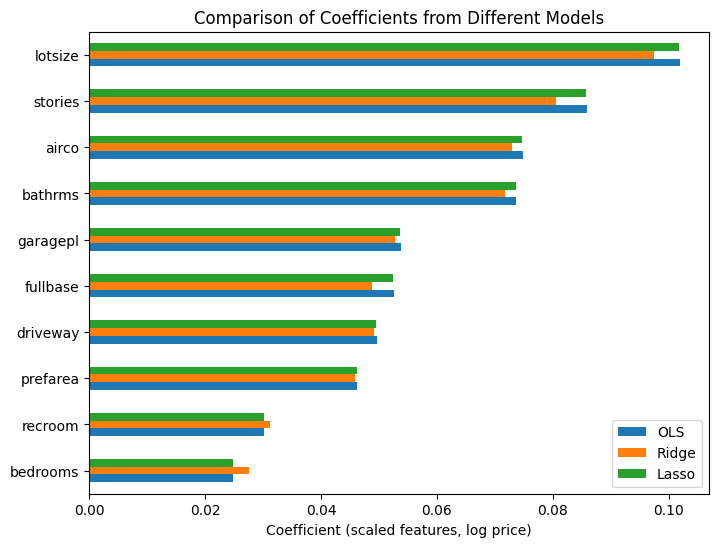

In [50]:
coefs = pd.DataFrame({
    'OLS': model.coef_,
    'Ridge': modelR.coef_,
    'Lasso': modelL.coef_
}, index=x.columns)

coefs = coefs.sort_values(by='OLS', ascending=True)

coefs.plot(kind='barh', figsize=(8,6))
plt.title('Comparison of Coefficients from Different Models')
plt.xlabel('Coefficient (scaled features, log price)')
plt.show()

General Summary:

1. there was little overfitting (train R^2 .665 vs test R^2 .632)
2. Regularization barely changed performance (R^2 about .63-.64 for every model)
3. Lasso kept all 10 features with a tiny alpha
4. Ridge redistributed weight among overlapping features

Further question: Why did Ridge raise bedrooms while lowering stories and lotsize?